# Group 21L — Optimization and sensitivity analysis

This notebook uses the supplied M4 and Yue sensitivity outputs. The companion Python files provide the full model, experiments, and report graphics. The optional solves require Gurobi and a valid license.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import optimization_analysis as report
root = Path.cwd()
original, sensitivity = report.audit_results()
report.make_figures(original, sensitivity)
display(original.round(4))


,probability,demand,sales,fill_rate,unmet_demand,unselected_product_demand,selected_product_unmet,expired_stock,overnight_carryover,day7_new_stock,loss
scenario,,,,,,,,,,,
low,0.3,1069.6512,939.6177,0.8784,130.0334,119.5383,10.4951,9.3269,39.4464,9.169,671.9678
typical,0.4,1185.9539,956.3549,0.8064,229.5990,132.5357,97.0634,1.7588,31.2331,0.000,1156.0005
high,0.3,1333.8864,958.1137,0.7183,375.7727,149.0678,226.7049,0.0000,27.6031,0.000,1884.3840


## Base-case planning decisions
The M4 solve and the sensitivity base are separately identified. Aggregate sensitivity fill rate is expected sales divided by expected demand.

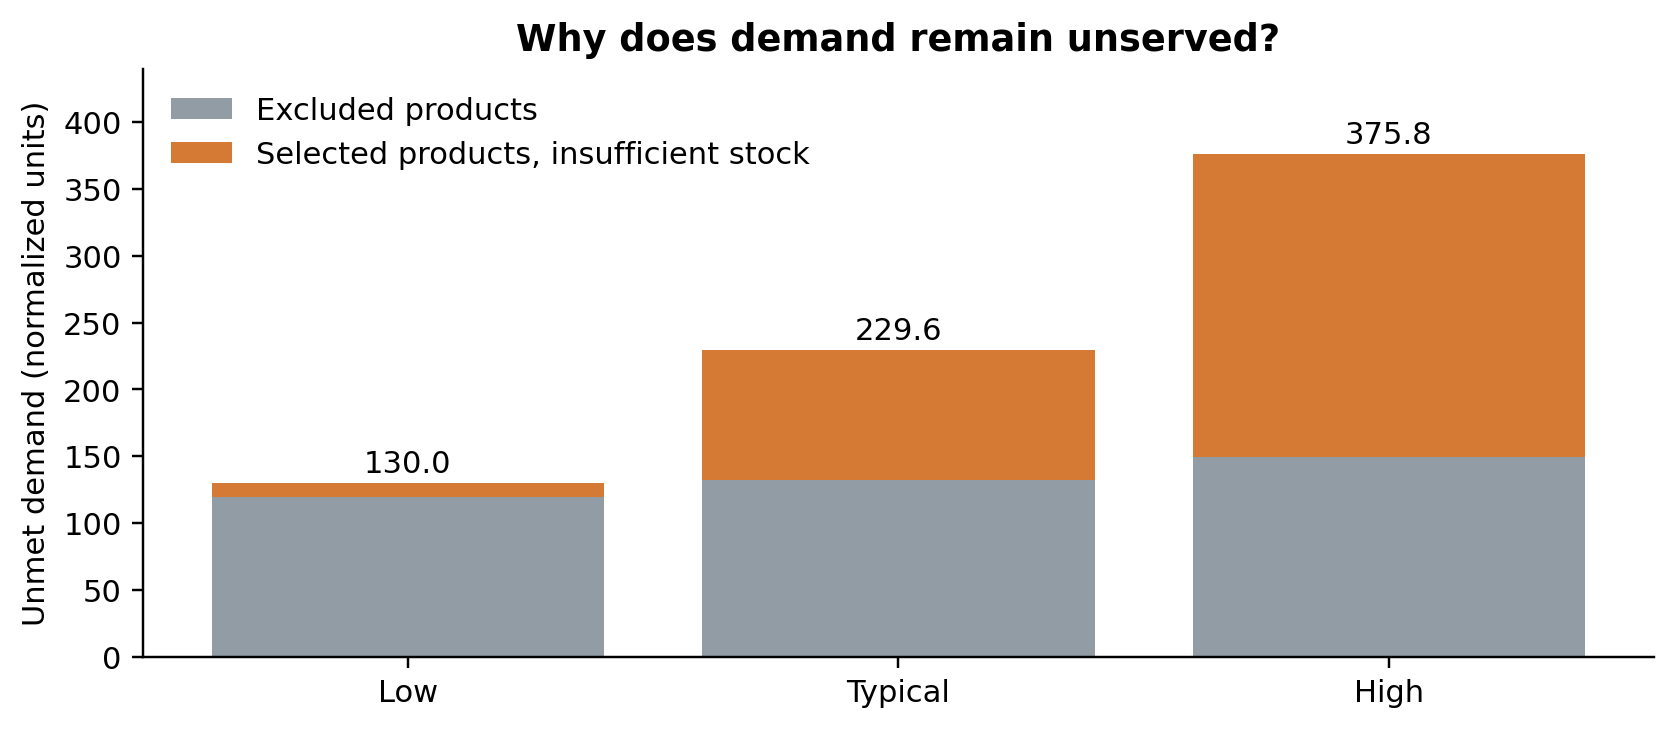

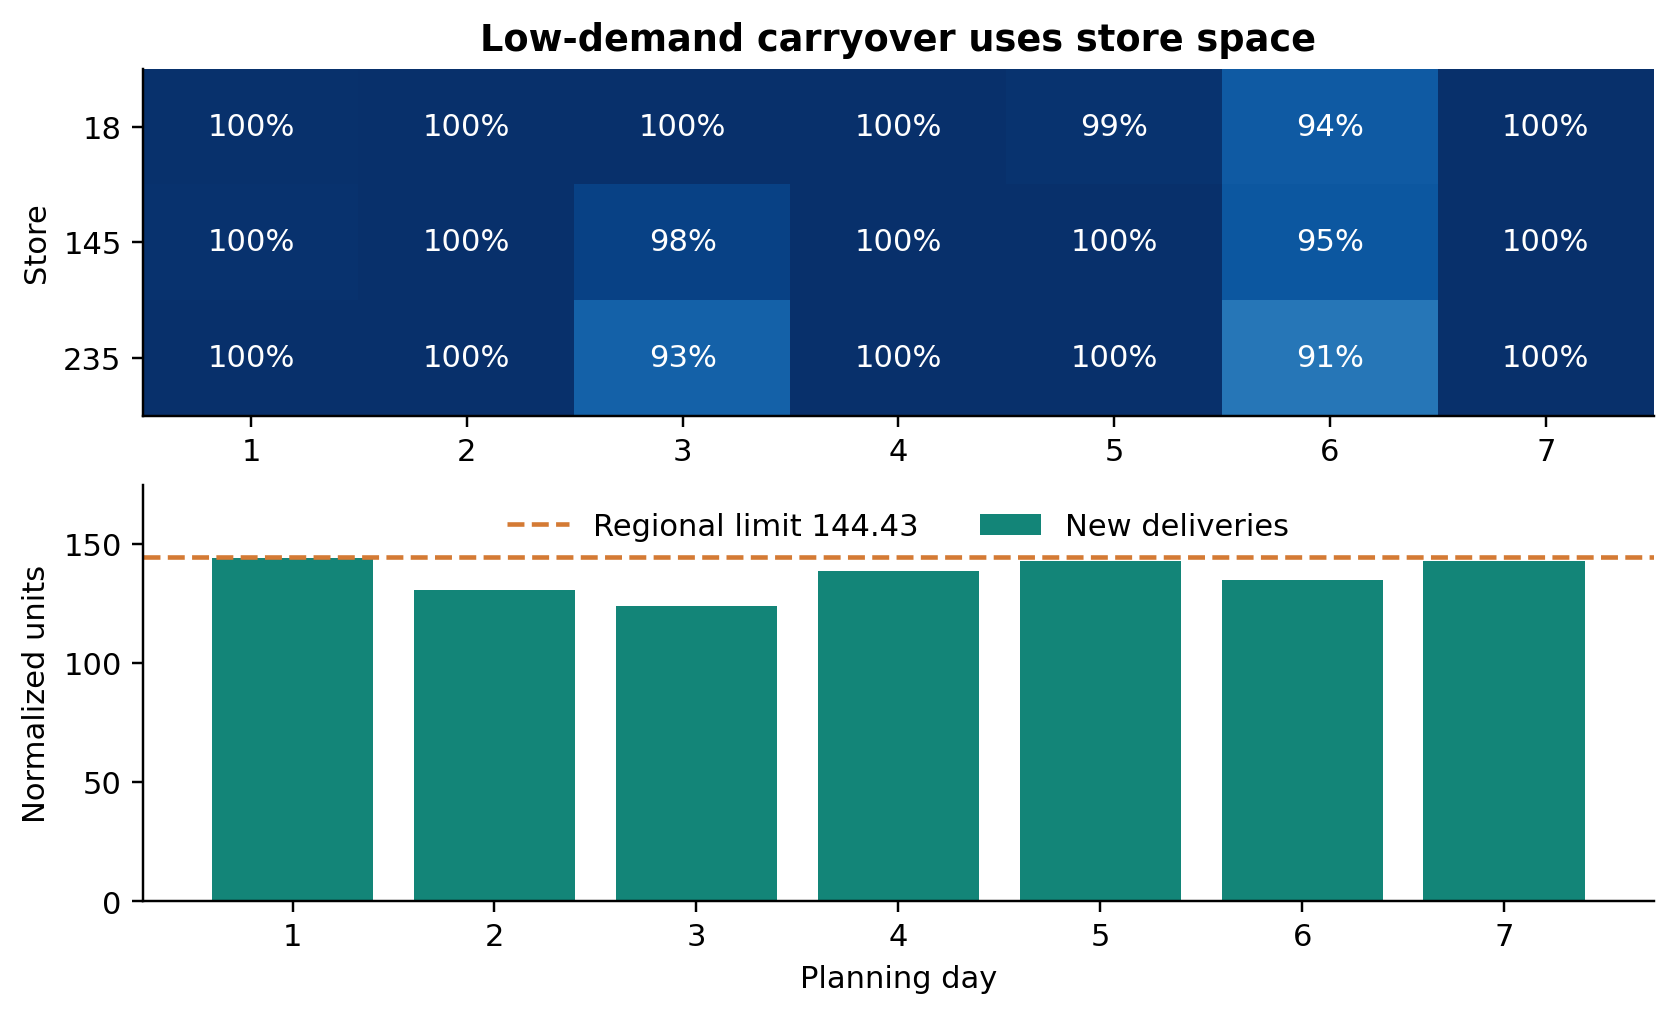

In [2]:
for name in ["fig01_shortage_sources", "fig02_inventory_and_supply"]:
    display(Image(filename=str(root / "figures" / (name + ".png"))))


## Resource sensitivity
Each case varies one parameter. Incumbent outcomes and MIP gaps are recorded together.

,case_id,group,parameter,value,status,objective,best_bound,mip_gap,runtime_seconds,exp_demand,exp_sales,exp_fill_rate,exp_unmet,exp_unselected_demand,exp_selected_unmet,exp_expired,exp_carryover,exp_day7_stock,base_weight_loss,weekly_delivery,products_selected,capacity_binding_store_days_any,capacity_binding_store_days_low,supply_binding_days,unused_supply,fill_rate_low,fill_rate_typical,fill_rate_high,assortment_changes_vs_base,capacity_marginal_value_total,supply_marginal_value_total,d_fill_rate_pp,d_unmet_pct,d_base_weight_loss_pct,d_objective_pct,objective_comparable,within_solver_tolerance
0,base,base,NaN,NaN,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,1229.2876,1202.7105,0.0216,60.0079,1195.4428,951.8584,0.7962,243.5844,133.5961,109.9883,3.4611,32.6458,2.7507,1229.2876,958.0703,60,12,12,1,52.9397,0.8784,0.8064,0.7183,0,28.88,-0.00,0.0000,0.0000,0.0000,0.0000,True,False
1,K_15,K,K,15.00,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,1640.4416,1578.0373,0.0380,60.0245,1195.4428,872.5861,0.7299,322.8567,251.7569,71.0998,7.6643,78.1896,5.7116,1640.4416,885.9620,45,11,11,0,125.0480,0.7894,0.7451,0.6642,15,16.87,-0.00,-6.6312,32.5441,33.4465,33.4465,True,False
2,K_25,K,K,25.00,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,1019.5485,1012.7195,0.0067,60.0105,1195.4428,992.3018,0.8301,203.1410,46.9331,156.2080,1.3409,10.7224,0.7160,1019.5485,994.3587,75,15,15,4,16.6513,0.9243,0.8377,0.7455,15,46.59,5.12,3.3831,-16.6034,-17.0618,-17.0618,True,False
3,K_29,K,K,29.00,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,964.8608,961.7534,0.0032,60.1916,1195.4428,1002.8994,0.8389,192.5434,0.0000,192.5434,0.8621,6.1402,0.1075,964.8608,1003.8691,87,17,17,5,7.1409,0.9363,0.8459,0.7526,27,68.59,5.12,4.2696,-20.9541,-21.5106,-21.5106,True,False
4,capacity_0.85,capacity,capacity_scale,0.85,OPTIMAL_WITHIN_CONFIGURED_GAP,1696.9834,1695.3105,0.0010,1.6858,1195.4428,856.1681,0.7162,339.2748,172.8307,166.4440,0.1966,2.0649,0.0000,1696.9834,856.3647,60,19,19,0,154.6453,0.8000,0.7221,0.6420,14,90.60,-0.00,-8.0046,39.2843,38.0461,38.0461,True,False
5,capacity_1.2,capacity,capacity_scale,1.20,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,1076.7407,1042.0697,0.0322,60.0203,1195.4428,986.1164,0.8249,209.3264,133.5961,75.7303,8.6364,83.1197,9.6967,1076.7407,1004.4496,60,7,7,6,6.5604,0.8882,0.8427,0.7530,0,9.25,8.88,2.8657,-14.0641,-12.4094,-12.4094,True,False
6,supply_0.85,supply,supply_scale,0.85,OPTIMAL_WITHIN_CONFIGURED_GAP,1680.4743,1680.4216,0.0000,0.5955,1195.4428,859.3585,0.7189,336.0843,166.7520,169.3324,0.0000,0.2632,0.0000,1680.4743,859.3585,60,0,0,7,0.0000,0.8034,0.7246,0.6443,14,-0.00,34.94,-7.7377,37.9745,36.7031,36.7031,True,False
7,supply_1.2,supply,supply_scale,1.20,FEASIBLE_INCUMBENT_NOT_PROVEN_OPTIMAL,1229.2682,1205.0768,0.0197,60.0106,1195.4428,951.8479,0.7962,243.5949,133.5961,109.9988,3.4301,32.4400,2.7507,1229.2682,958.0287,60,13,13,0,255.1833,0.8784,0.8064,0.7182,0,28.88,-0.00,-0.0009,0.0043,-0.0016,-0.0016,True,True


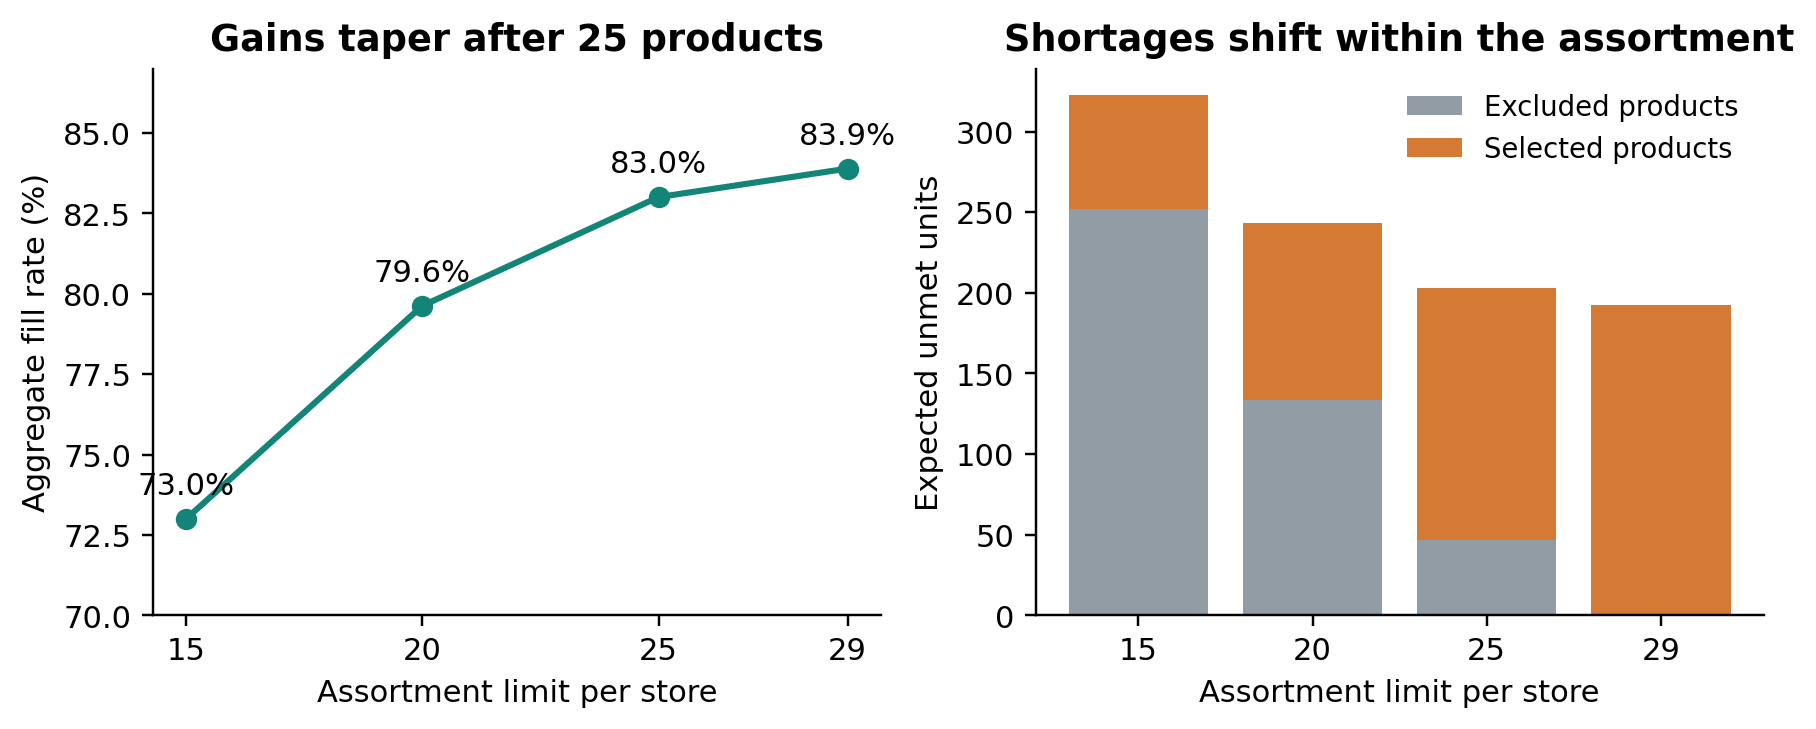

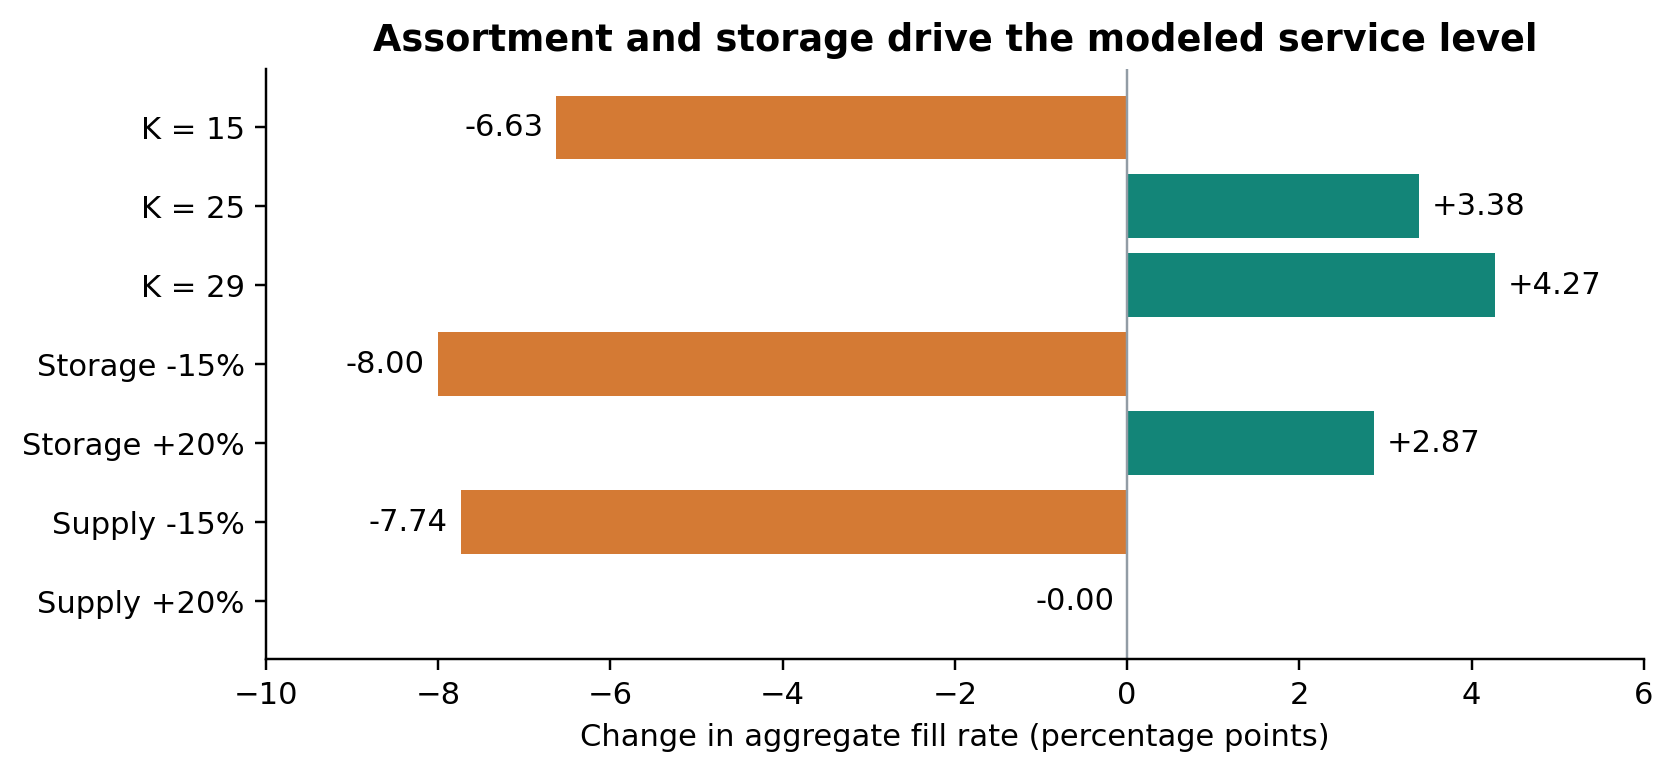

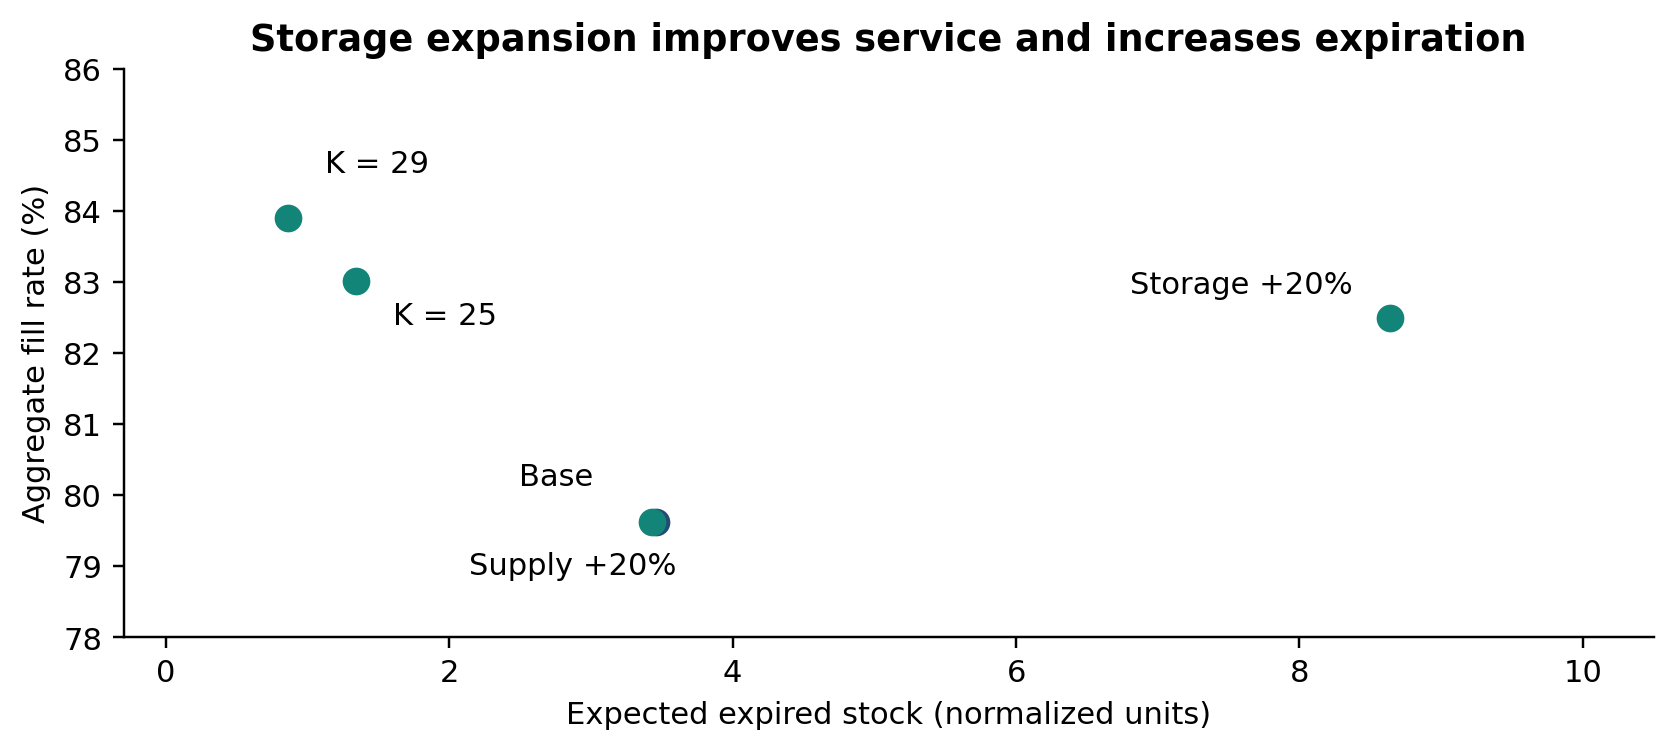

,case_id,base_weight_loss,exp_fill_rate,exp_expired,mip_gap,assortment_changes_vs_base
0,alpha_2,1229.5812,0.7960,2.3616,0.0173,0
1,alpha_10,1229.2873,0.7962,3.5024,0.0215,0
2,h_0,1230.0826,0.7963,3.5680,0.0186,0
3,h_0.5,1229.2188,0.7962,3.0911,0.0207,0
4,tau_0.25,1229.2875,0.7962,3.4611,0.0201,0
5,tau_1,1229.2541,0.7962,3.2851,0.0202,0


In [3]:
display(pd.read_csv(root / "results/resource_comparison.csv").round(4))
for name in ["fig03_assortment", "fig04_resource_effects", "fig05_service_waste"]:
    display(Image(filename=str(root / "figures" / (name + ".png"))))
display(pd.read_csv(root / "results/penalty_comparison.csv").round(4))


## Optional optimization execution
Run these commands from the project folder when additional solves are required.

```bash
python optimization_analysis.py --solve-base
python optimization_analysis.py --solve-sensitivity --time-limit 60
```

Model definitions are in `gurobi_model.py`. Yue’s full experiment implementation is in `sensitivity_analysis.py`. Exported planning results require a separate common-policy holdout evaluation before an overall policy recommendation.